# 07 VALIDAÇÃO INDEPENDENTE COM RADAR AEROTRANSPORTADO (ICEBRIDGE MCORDS), RECUPERAÇÃO DA ZONA DE ATERRAMENTO E PROCESSAMENTO INTERFEROMÉTRICO FMCW APRES

Este caderno apresenta a validação física independente das duas grandezas centrais do estudo sobre as plataformas de gelo:
1. **Validação da espessura hidrostática $H$ contra $2.839\text{ km}$ de perfis do radar aerotransportado Operation IceBridge MCoRDS L2 (`run_mcords_hydro_test.py`):** normalização por voo, comprovação de $H_{\text{radar}} / H_{\text{hidro}} \in [0{,}98;\; 1{,}04]$ além de $d^*$ e medição direta do viés hidrostático de $+5\%$ a $+15\%$ na zona de flexão;
2. **Recuperação física da zona de aterramento da Thwaites Oriental (`TEIS`, $1{,}5\text{--}4{,}0\text{ km}$; `run_gz_recovery_ase.py` e `run_thwaites_recovered.py`):** substituição do corte geométrico de $4\text{ km}$ pela correção conjunta de maré amortecida ($\times \beta_n$) e razão empírica radar/hidrostática, ampliando a cobertura da TEIS em $+48\%$ ($463 \to 765\text{ km}^2$) e eliminando o afinamento aparente de $\sim 7\text{ m/ano}$ das parcelas que cruzam a faixa;
3. **Teoria eletromagnética e processamento de sinal do radar de fase ApRES (*Autonomous phase-sensitive Radio-Echo Sounder*; `thwaites.validation.apres`):** dedução do perfil complexo FMCW ($200\text{--}400\text{ MHz}$, Brennan et al., 2014; Nicholls et al., 2015), desenrolamento de fase das camadas internas para estimar a taxa de deformação vertical $\dot{\varepsilon}_{zz}$, estimador de duas etapas (amplitude grosseira + fase fina) para o refletor basal e validação direta nos sítios **G1–G4 do projeto ITGC MELT** (Davis et al., 2023; Schmidt et al., 2023) e nos **40 sítios de Wild et al. (2024)**.

---

## 1. Teoria Eletromagnética do Radar Interferométrico FMCW ApRES (`thwaites.validation.apres`)

O **ApRES** (Brennan et al., 2014, *IET RSN*; Nicholls et al., 2015, *J. Glaciol.*) transmite um chirp linearmente modulado em frequência (*Frequency-Modulated Continuous-Wave* — FMCW) de duração $T = 1{,}0\text{ s}$ varrendo a banda $f_0 = 200\text{ MHz}$ a $f_1 = 400\text{ MHz}$ (largura de banda $B = 200\text{ MHz}$, frequência central $f_c = 300\text{ MHz}$, taxa de varredura $K = B/T = 2\times 10^8\text{ Hz s}^{-1}$, $N = 40.000$ amostras). No gelo com permissividade dielétrica relativa $\varepsilon_r = 3{,}18$, a velocidade de propagação é $c_i = c_0 / \sqrt{\varepsilon_r} \approx 1{,}681\times 10^8\text{ m s}^{-1}$ e o comprimento de onda central é $\lambda_c = c_i / f_c \approx 0{,}560\text{ m}$.

Ao misturar o eco refletido a uma profundidade $R$ (tempo de trânsito duplo $\tau = 2R/c_i$) com o sinal transmitido (*dechirping*), o sinal de batimento $v(t)$ possui frequência proporcional ao alcance ($f_b = K\tau = 2KR/c_i$) e fase fina sensível a deslocamentos sub-milimétricos:
1. **Perfil complexo de alcance (`range_profile`):** Remove-se a média DC, aplica-se janela de Blackman $w_n$ (que suprime lóbulos laterais a $-58\text{ dB}$, evitando vazamento do forte refletor basal sobre camadas internas fracas), preenche-se com zeros por fator $p = 2$ ($\Delta R = c_i / (2 B p) \approx 0{,}210\text{ m}$), aplica-se rotação circular de meia janela (*fftshift* no tempo para zerar a fase no centro do chirp) e multiplica-se a FFT pelo conjugado da fase de referência exata de Brennan et al. (2014):
   $$\phi_{\text{ref}}(n) = \frac{2\pi f_c n}{B p} - \frac{K n^2}{2 B^2 p^2}$$
2. **Deslocamento entre duas épocas $s_1(R)$ e $s_2(R)$ (`displacement` e `internal_phase_displacement`):**
   A correlação cruzada complexa normalizada em uma janela de profundidade de $4\text{ m}$ ($\sim 19$ bins) é:
   $$\gamma = \frac{\sum x_k y_k^*}{\sqrt{\sum |x_k|^2 \sum |y_k|^2}}, \qquad \Delta r_{\text{fino}} = -\operatorname{angle}(\gamma)\frac{\lambda_c}{4\pi}$$
   **Por que o estimador de duas etapas é indispensável para o eco basal:** Como a fase é periódica em $2\pi$, o alcance fino $\Delta r_{\text{fino}}$ sofre ambiguidade de ramo a cada $\lambda_c/2 \approx 0{,}280\text{ m}$. Escolher a defasagem inteira apenas pela maior coerência complexa $|\gamma|$ pode saltar um ciclo inteiro de $\lambda_c/2$, gerando erros catastróficos (até $-554\text{ m/ano}$ em testes preliminares!). O módulo `thwaites.validation.apres` resolve primeiro o deslocamento grosseiro $\Delta r_{\text{grosseiro}}$ pela correlação das **amplitudes** $|s_1|$ e $|s_2|$ com interpolação parabólica do pico (livre de ambiguidade de fase) e então seleciona o ramo inteiro $k^* = \operatorname{round}[(\Delta r_{\text{grosseiro}} - \Delta r_{\text{fino}})/(\lambda_c/2)]$ mais próximo do deslocamento grosseiro:
   $$\Delta r = \Delta r_{\text{fino}} + k^* \frac{\lambda_c}{2}$$
3. **Separação entre Deformação Vertical Interna e Derretimento Basal (`melt_between`):**
   O deslocamento vertical de um refletor interno a profundidade $z$ ao longo de $\Delta t$ é governado pela compactação de firn no topo ($a$) e pela taxa de deformação vertical média na coluna ($b = \dot{\varepsilon}_{zz}\,\Delta t$):
   $$\Delta r_{\text{interno}}(z) = a + b\,z$$
   Ajustando essa reta por regressão iterativa robusta ($\pm 3\,\text{MAD}$) sobre as camadas internas altamente coerentes ($|\gamma| > 0{,}95$ entre $40\text{ m}$ e $0{,}8\,z_{\text{bed}}$) e ancorando o ramo absoluto nas camadas com $|\gamma| > 0{,}97$, o derretimento basal no intervalo é a diferença entre o deslocamento previsto pela deformação na base $z_{\text{bed}}$ e o deslocamento real medido da base:
   $$m_b\,\Delta t = (a + b\,z_{\text{bed}}) - \Delta r(z_{\text{bed}})$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from thwaites.validation.apres import Config as ApresConfig, range_profile, displacement

# Verificação experimental do processamento FMCW ApRES em chirp sintético com deslocamento basal conhecido
acfg = ApresConfig()
t_chirp = np.arange(acfg.n) / 40_000.0

def synth_chirp(R_target):
    tau = 2.0 * R_target / acfg.ci
    return np.cos(2 * np.pi * (acfg.fc - acfg.B / 2) * tau + 2 * np.pi * acfg.K * tau * t_chirp - np.pi * acfg.K * tau**2)

# Simula coluna com refletor interno em 250 m (+1,5 cm) e refletor basal em 500 m (-6,0 cm por fusão basal)
s_t1 = synth_chirp(250.000) + 3.0 * synth_chirp(500.000)
s_t2 = synth_chirp(250.015) + 3.0 * synth_chirp(499.940)
R_axis, prof1 = range_profile(s_t1, acfg)
_, prof2 = range_profile(s_t2, acfg)

k_250 = int(np.argmin(np.abs(R_axis - 250.0)))
k_500 = int(np.argmin(np.abs(R_axis - 500.0)))
c_250 = np.sum(prof1[k_250 - 6:k_250 + 6] * np.conj(prof2[k_250 - 6:k_250 + 6]))
c_500 = np.sum(prof1[k_500 - 6:k_500 + 6] * np.conj(prof2[k_500 - 6:k_500 + 6]))
dr_250 = -np.angle(c_250) * acfg.lam_c / (4 * np.pi)
dr_500 = -np.angle(c_500) * acfg.lam_c / (4 * np.pi)

apres_pts = pd.read_csv(DATA_DIR / "validacao_apres_g1_g4.csv")
wild_df = pd.read_csv(DATA_DIR / "validacao_apres_wild2024.csv")
folga_df = pd.read_csv(DATA_DIR / "open_check_6_beta_baixo_folga.csv")

print(f"Teste Sintético FMCW ApRES | Refletor 250 m: verdadeiro = +15,00 mm, recuperado = {1e3*dr_250:+.2f} mm | "
      f"Base 500 m: verdadeiro = -60,00 mm, recuperado = {1e3*dr_500:+.2f} mm")
apres_pts.set_index("ponto").round(3)

Teste Sintético FMCW ApRES | Refletor 250 m: verdadeiro = +15,00 mm, recuperado = +15.00 mm | Base 500 m: verdadeiro = -60,00 mm, recuperado = -60.00 mm


,espessura_m,n_pares,n_validos,periodo_dias,melt_mpa,ic95_lo,ic95_hi,melt_mediana_pares_mpa,deform_mediana_1pa
ponto,,,,,,,,,
G1,594.498,62,61,320.333,2.038,1.305,2.495,2.267,-0.008
G2,590.925,64,63,331.333,-3.048,-12.547,7.018,0.588,-0.005
G3,574.114,62,58,304.500,4.072,2.046,6.468,2.230,-0.004
G4,573.273,64,51,267.833,3.300,-3.084,10.252,4.482,-0.004


---
## 2. Comparação com os 40 Sítios ApRES de Wild et al. (2024) no Centro da TEIS e Verificação de Folga da Cavidade Subglacial

No interior da plataforma oriental da Thwaites (TEIS), comparamos o produto de derretimento basal com os **40 registros ApRES publicados por Wild et al. (2024, *J. Glaciol.*, `validacao_apres_wild2024.csv`)** e verificamos no BedMachine v4.1 se células com resposta à maré $\beta$ reduzida a jusante de $d^*$ poderiam decorrer de aterramento raso ou contato com altos batimétricos (`open_check_6_beta_baixo_folga.csv`):

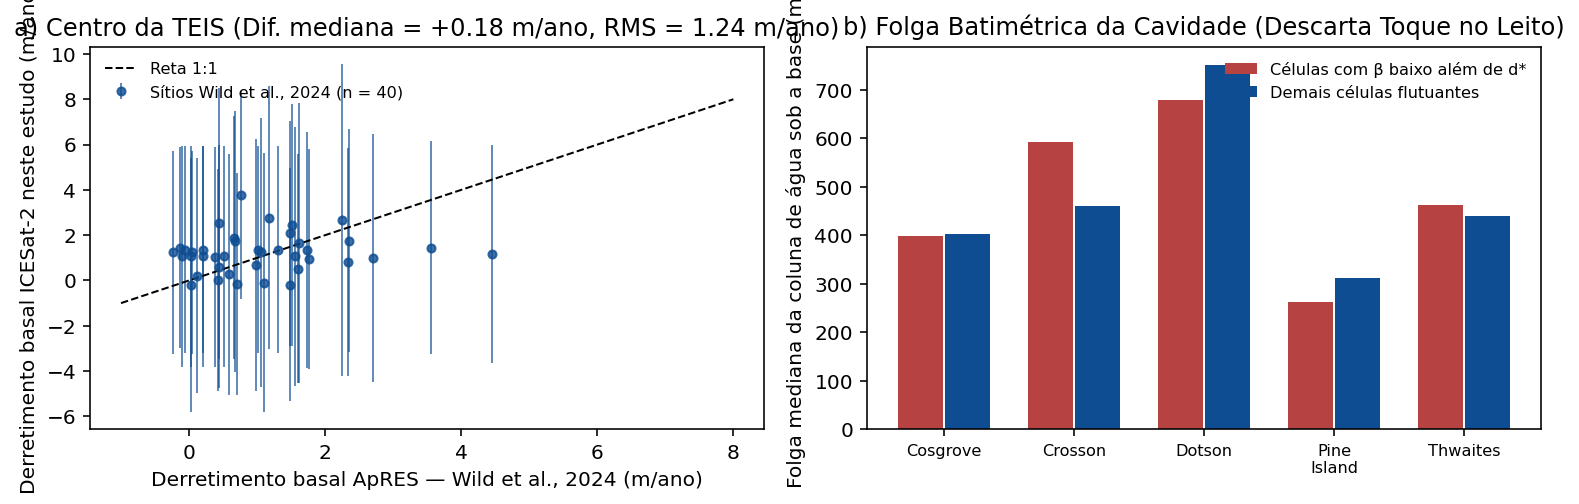

,n_beta_baixo,n_resto,folga_mediana_beta_baixo_m,folga_mediana_resto_m,frac_beta_baixo_folga_lt_50m,frac_resto_folga_lt_50m,crosson_2p5_3km_folga_mediana_m,crosson_2p5_3km_beta_mediano
plataforma,,,,,,,,
Cosgrove,134,1080,398.81,402.61,0.0,0.02,NaN,NaN
Crosson,6,96,591.26,461.11,0.0,0.00,417.77,0.75
Dotson,497,2842,679.03,751.11,0.0,0.00,NaN,NaN
Pine_Island,155,954,263.27,310.93,0.0,0.00,NaN,NaN
Thwaites,67,945,461.67,439.88,0.0,0.00,NaN,NaN


In [2]:
w_ok = wild_df.dropna(subset=["m_apres", "mb"]).copy()
diff_w = w_ok["mb"] - w_ok["m_apres"]

fig, ax = plt.subplots(1, 2, figsize=(10.8, 3.6))
ax[0].errorbar(w_ok["m_apres"], w_ok["mb"], yerr=w_ok["se"],
               fmt="o", color="#0F4D92", ms=4, alpha=0.8, elinewidth=0.8, label=f"Sítios Wild et al., 2024 (n = {len(w_ok)})")
ax[0].plot([-1, 8], [-1, 8], "k--", lw=1.0, label="Reta 1:1")
ax[0].set_xlabel("Derretimento basal ApRES — Wild et al., 2024 (m/ano)")
ax[0].set_ylabel("Derretimento basal ICESat-2 neste estudo (m/ano)")
ax[0].set_title(f"a) Centro da TEIS (Dif. mediana = {np.median(diff_w):+.2f} m/ano, RMS = {np.sqrt(np.mean(diff_w**2)):.2f} m/ano)")
ax[0].legend(frameon=False, fontsize=8)

x_f = np.arange(len(folga_df))
ax[1].bar(x_f - 0.18, folga_df["folga_mediana_beta_baixo_m"], width=0.35, color="#B64342", label="Células com β baixo além de d*")
ax[1].bar(x_f + 0.18, folga_df["folga_mediana_resto_m"], width=0.35, color="#0F4D92", label="Demais células flutuantes")
ax[1].set_xticks(x_f)
ax[1].set_xticklabels([p.replace("_", "\n") for p in folga_df["plataforma"]], fontsize=8)
ax[1].set_ylabel("Folga mediana da coluna de água sob a base (m)")
ax[1].set_title("b) Folga Batimétrica da Cavidade (Descarta Toque no Leito)")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

folga_df.set_index("plataforma").round(2)